# Assignment 2 — Baselines and Basic Deep-Learning Models

**Purpose:** Compare persistence, LSTM, and causal 1D CNN models under one feature contract.

This notebook is an executable evidence view over the shared local pipeline. The
command-line runner and notebook call the same stage implementation, preventing code
drift. Completed artifacts are reused; no Google Colab or Google Drive runtime is used.


In [1]:
# Local WSL project bootstrap. Dependency installation belongs to the
# locked project environment and is intentionally not repeated in notebooks.
from pathlib import Path
import json
import os
import platform
import sys

candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [candidate, *candidate.parents] if (path / "shared").exists()),
    candidate,
)
if not (PROJECT_ROOT / "shared").exists():
    raise FileNotFoundError(
        "Open this notebook from the local odl-assignment project root."
    )
os.environ["ODL_PROJECT_ROOT"] = str(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from shared.config import PATHS
from shared.runtime import RuntimeOptions
from shared.workflow import run_stage

OPTIONS = RuntimeOptions.from_environment()
print("Project root:", PROJECT_ROOT)
print("Run mode:", OPTIONS.mode)
print("Device policy:", OPTIONS.device)
print("WSL distribution:", os.getenv("WSL_DISTRO_NAME", "not detected"))


I0000 00:00:1786540920.353841    5600 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786540920.410828    5600 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Project root: /home/nicholas/code/odl-assignment
Run mode: smoke
Device policy: gpu
WSL distribution: Ubuntu-24.04


I0000 00:00:1786540921.583443    5600 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Run the shared stage or load its verified completed result.
STAGE_SUMMARY = run_stage("baselines", options=OPTIONS)
STAGE_SUMMARY


{'selected_model': 'cnn',
 'selected_forward_fill_limit_hours': 24,
 'selected_lookback_hours': 24,
 'rolling_validation_mae': 31.11111732375482,
 'final_training_seconds': {'lstm': 4.0574660339998445,
  'cnn': 5.2457036109999535},
 'folds': 1,
 'run_mode': 'smoke'}

In [3]:
# Record the exact runtime used for this output when preflight evidence exists.
environment_path = PATHS.environment_artifacts / f"environment_{OPTIONS.mode}.json"
ENVIRONMENT = (
    json.loads(environment_path.read_text(encoding="utf-8"))
    if environment_path.exists()
    else {"status": "preflight evidence not yet generated"}
)
ENVIRONMENT


{'captured_at_utc': '2026-08-12T13:18:29.136112+00:00',
 'project_root': '/home/nicholas/code/odl-assignment',
 'platform': 'Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39',
 'system': 'Linux',
 'release': '6.6.87.2-microsoft-standard-WSL2',
 'python': '3.12.3',
 'wsl_distribution': 'Ubuntu-24.04',
 'device': 'gpu',
 'tensorflow_gpu_devices': ['/physical_device:GPU:0'],
 'batch_size': 256,
 'mixed_precision': False,
 'nvidia_smi': {'available': True,
  'name': 'NVIDIA GeForce RTX 3050 Laptop GPU',
  'driver_version': '591.74',
  'memory.total': '4096',
  'memory.used': '665',
  'utilization.gpu': '3',
  'temperature.gpu': '57',
  'power.draw': '18.22'},
 'packages': {'tensorflow': '2.21.0',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'pyarrow': '25.0.0',
  'scikit-learn': '1.9.0',
  'matplotlib': '3.11.1',
  'seaborn': '0.13.2'},
 'git': {'available': True,
  'revision': '8cbcae3e1948b87b42012417b61d73ab859f470e',
  'dirty': True},
 'experiment_config': {'methodology_versi

## Baseline forecasts

**Decision.** Compare neural networks with lag-1 persistence and true 24-hour daily
persistence. **Alternatives.** Reporting neural models alone cannot show whether they
beat strong short-lag autocorrelation or daily recurrence. **Evidence.** The EDA
reports strong lag-1 and daily autocorrelation. **Trade-off.** Naive baselines are
intentionally simple, but provide the minimum credible forecasting reference.


In [4]:
import pandas as pd
from IPython.display import Image, display

suffix = OPTIONS.artifact_suffix
baseline_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"validation_baseline_metrics{suffix}.csv"
)
display(baseline_metrics)


,model,mae,rmse,r2,smape_percent
0,daily_persistence,57.677766,82.270461,-0.388915,80.507843
1,persistence,11.277624,22.447436,0.896600,21.524701


## Controlled architecture comparison

**Decision.** Compare an LSTM with a causal dilated 1D CNN using identical features,
rolling folds, loss, and primary metric. LSTM is designed for gated sequential memory
([Hochreiter and Schmidhuber](https://doi.org/10.1162/neco.1997.9.8.1735)); the CNN is
a parallel local-pattern alternative whose final causal state preserves recent
information ([Bai et al.](https://arxiv.org/abs/1803.01271)). **Trade-off.** This is an
architecture comparison, not proof that either family is universally superior.


,model,mae,mae_std,rmse,r2,smape_percent,parameters,training_seconds,median_best_epoch
0,cnn,31.111117,NaN,50.536640,0.475917,50.874996,22913,4.703213,1.0
1,lstm,41.389352,NaN,65.212473,0.127332,61.181542,29249,3.377172,1.0


{'selected_model': 'cnn',
 'selection_metric': 'mean_rolling_validation_mae',
 'run_mode': 'smoke',
 'config_hash': '3c74d277bc97ef6a',
 'source_fingerprint': '5bd159fcfc91988987f735c6bcbdd93d340a9bde97152f2b8fdc12c7edd821a1'}

,model,fold,seed,source_fingerprint,n,mae,rmse,r2,smape_percent,best_epoch,epochs_recorded,parameters,training_seconds
0,lstm,fold_1,42,5bd159fcfc91988987f735c6bcbdd93d340a9bde97152f...,8469,41.389352,65.212473,0.127332,61.181542,1,1,29249,3.377172
1,cnn,fold_1,42,5bd159fcfc91988987f735c6bcbdd93d340a9bde97152f...,8469,31.111117,50.536640,0.475917,50.874996,1,1,22913,4.703213


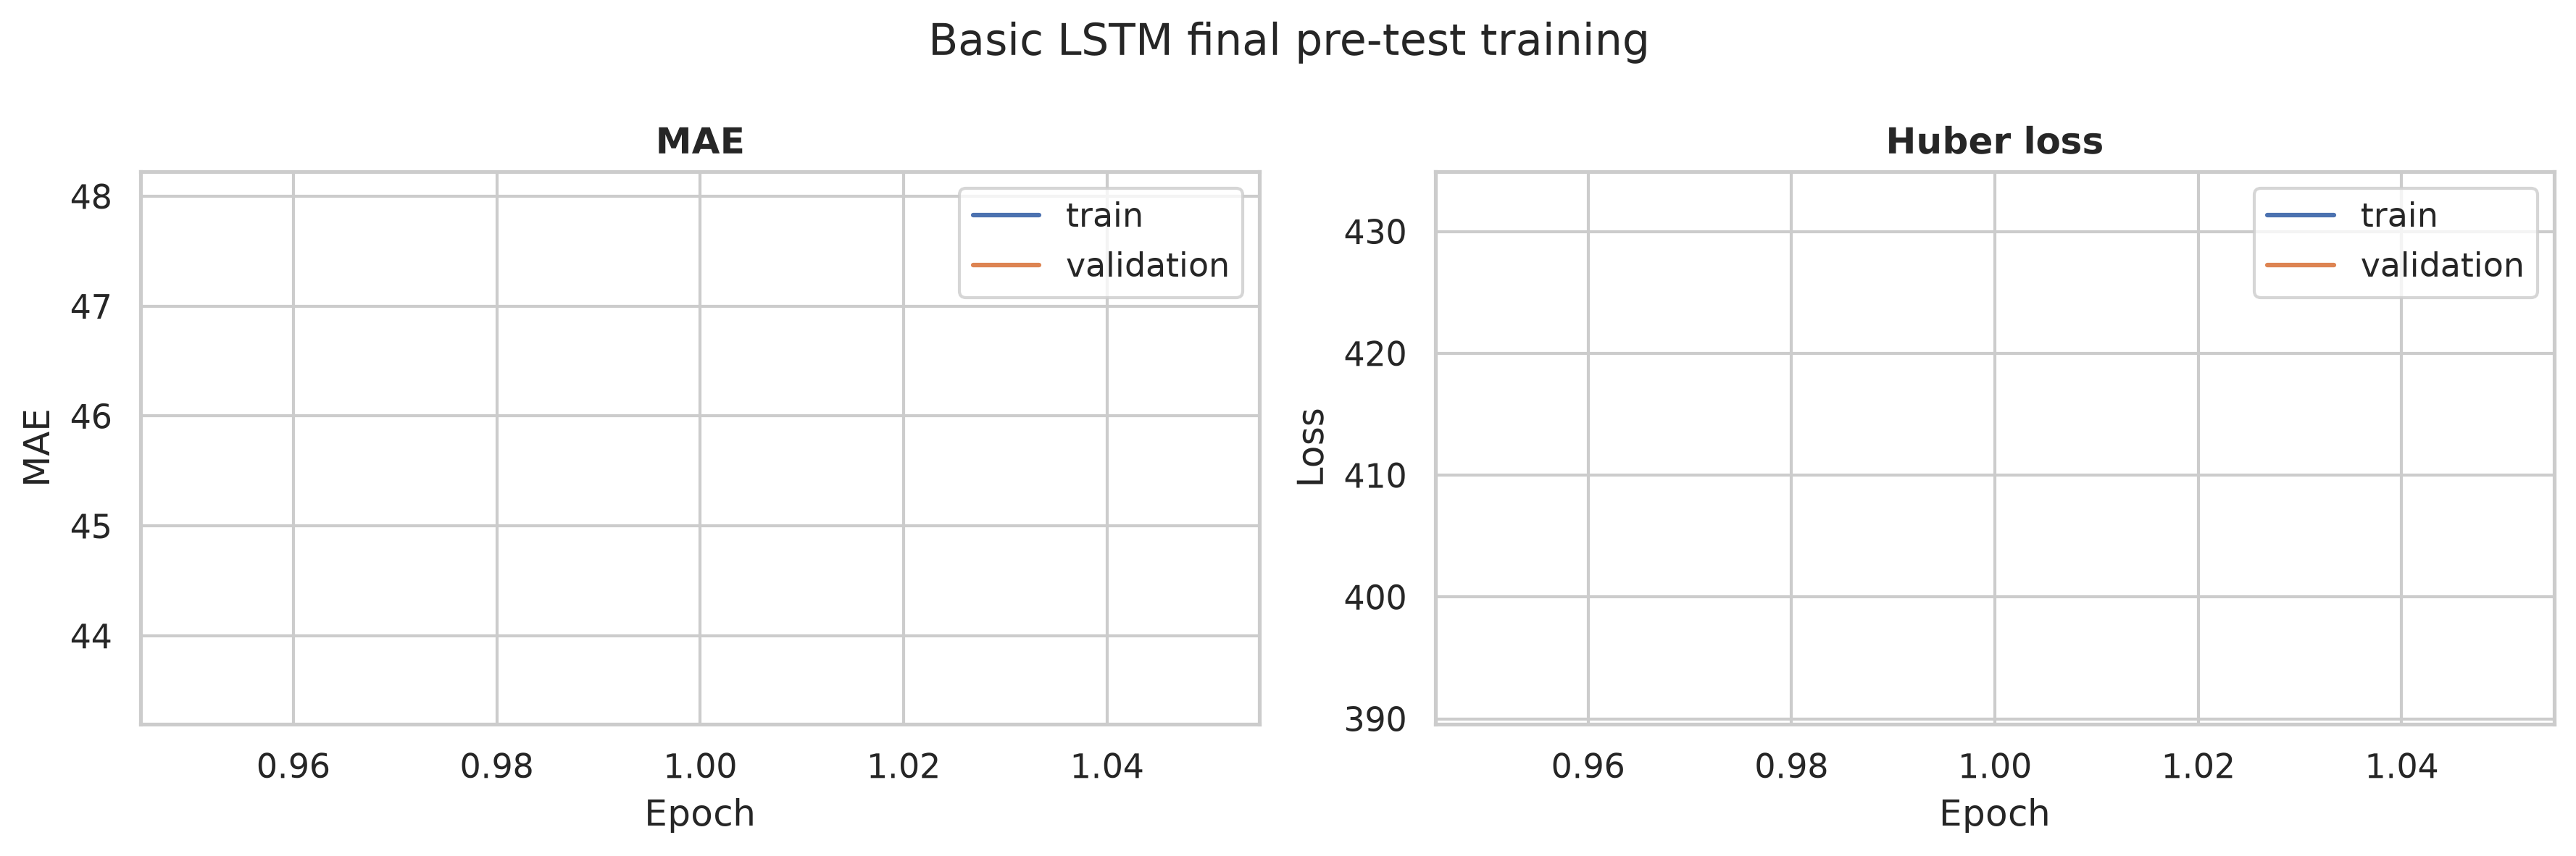

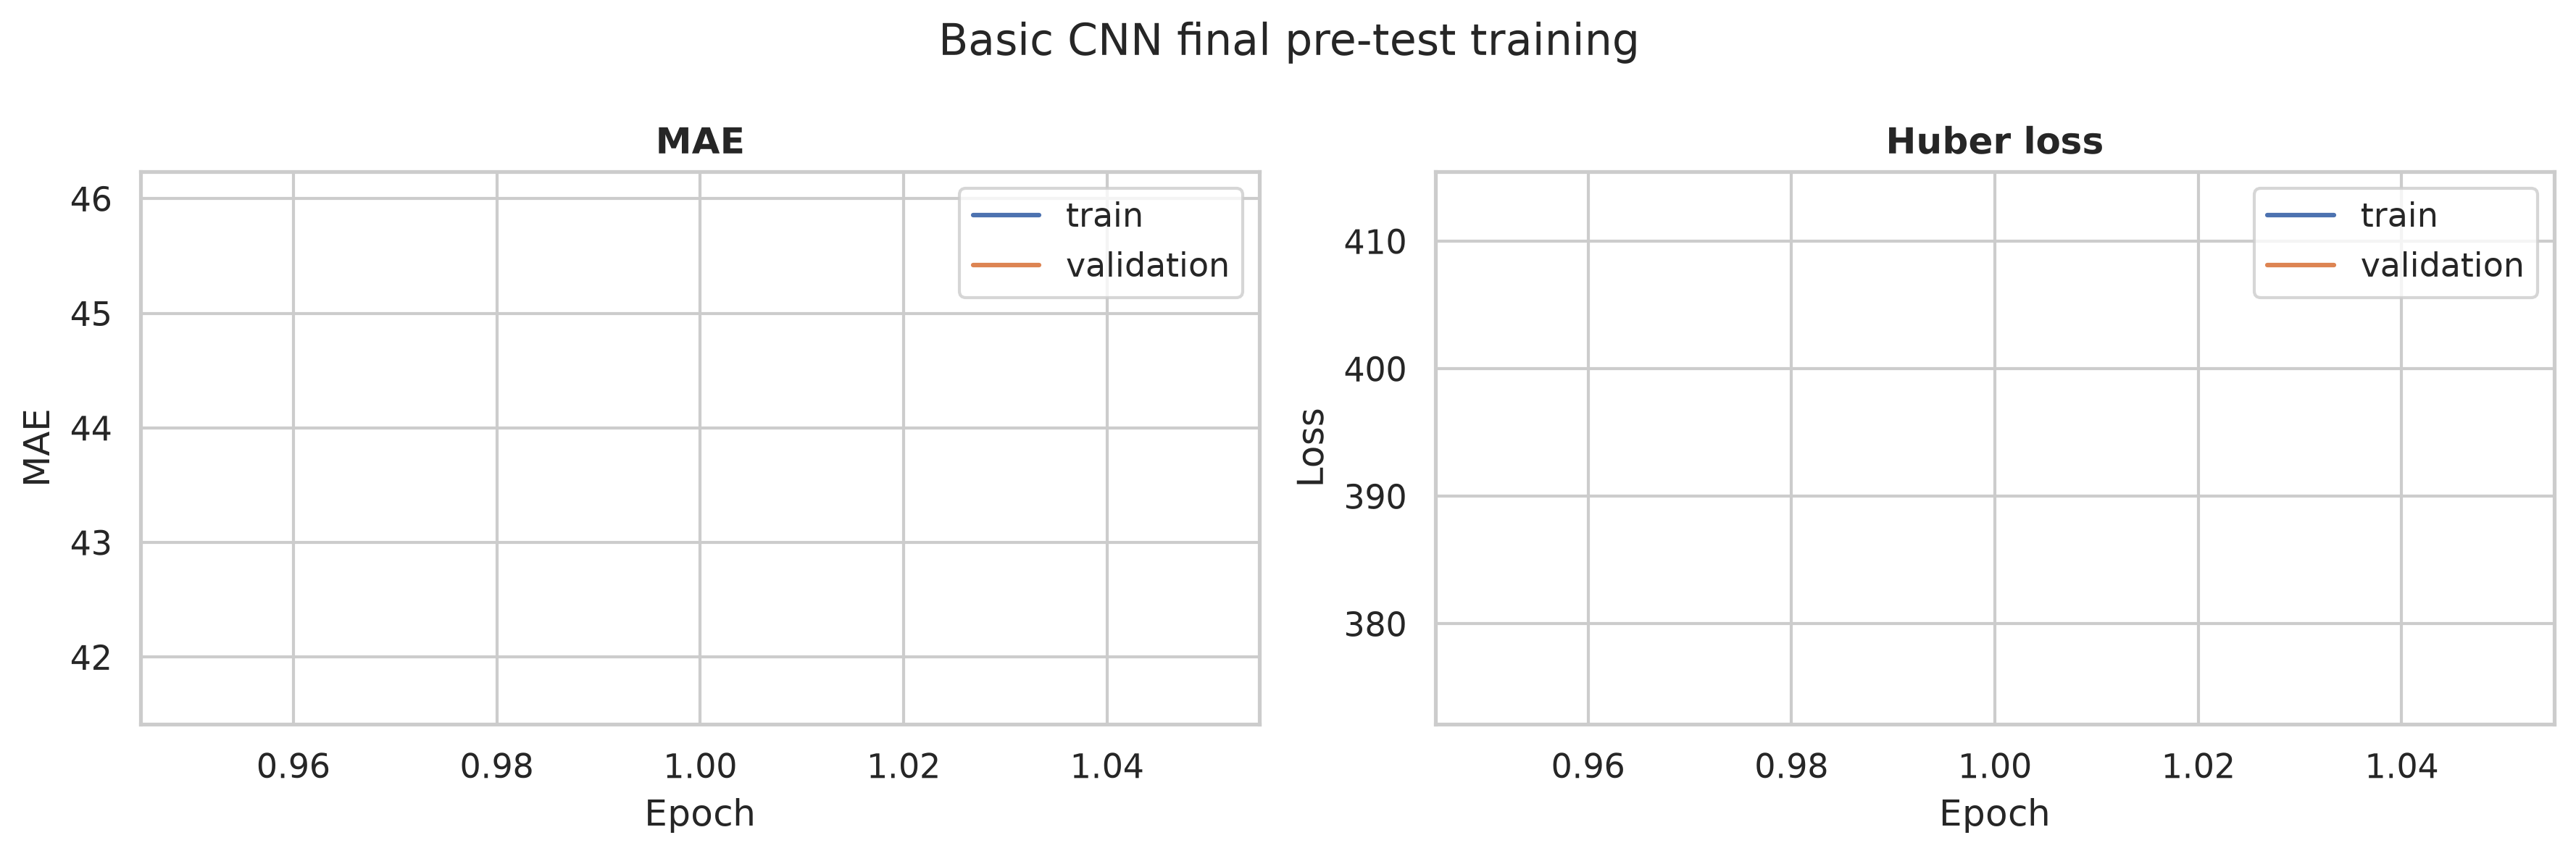

Selected architecture: CNN


In [5]:
comparison = pd.read_csv(
    PATHS.assignment2_tables / f"basic_model_comparison{suffix}.csv"
)
selection = json.loads(
    (PATHS.models / f"selected_architecture{suffix}.json").read_text(encoding="utf-8")
)
display(comparison)
display(selection)
display(pd.read_csv(
    PATHS.assignment2_tables / f"basic_rolling_results{suffix}.csv"
))
display(Image(filename=str(
    PATHS.assignment2_figures / f"basic_lstm_training{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"basic_cnn_training{suffix}.png"
)))
print("Selected architecture:", selection["selected_model"].upper())
